# **MÓDULO 39 - Exercicio - Aplicando XGboost**

Nessa atividade vocês usarão uma base já connhecida, a base de propensão a compra de carros.
Já utilizamos essa base antes, nessa atividade, você deve carregar a base, realizar os tratamentos necessários, rodar o XGBoost, encontrar as principais variaveis.
Vamos lá!

In [1]:
import xgboost as xgb
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, precision_score, recall_score, f1_score
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder

# 1. Carrega a base de dados, verifique os tipos de dados, dados faltantes e drop a coluna ID.


In [2]:
# Carregamento da base
df = pd.read_csv('../data/CARRO_CLIENTES.csv')

# Visualização inicial
print(df.head())

# Informações gerais
print(df.info())

# Verificação de valores ausentes
print(df.isnull().sum())

# Removendo a coluna de identificação
df = df.drop('User ID', axis=1)

print('\nBase após remoção da coluna ID:')
print(df.head())

   User ID Gender  Age  AnnualSalary  Purchased
0      385   Male   35         20000          0
1      681   Male   40         43500          0
2      353   Male   49         74000          0
3      895   Male   40        107500          1
4      661   Male   25         79000          0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   User ID       1000 non-null   int64 
 1   Gender        1000 non-null   object
 2   Age           1000 non-null   int64 
 3   AnnualSalary  1000 non-null   int64 
 4   Purchased     1000 non-null   int64 
dtypes: int64(4), object(1)
memory usage: 39.2+ KB
None
User ID         0
Gender          0
Age             0
AnnualSalary    0
Purchased       0
dtype: int64

Base após remoção da coluna ID:
  Gender  Age  AnnualSalary  Purchased
0   Male   35         20000          0
1   Male   40         43500          0
2   

# 2. Aplique o Label Encoder para a coluna Gender e exclua a coluna categórica.

In [3]:
# Aplicando Label Encoder na variável Gender
le = LabelEncoder()

# Cria uma nova coluna numérica para representar o gênero
df['Gender_Encoded'] = le.fit_transform(df['Gender'])

# Remove a coluna categórica original de forma clara e legível
# O inplace=True altera o próprio DataFrame sem precisar reatribuir df = df.drop(...)
df.drop(columns=['Gender'], inplace=True)

print('Base após codificação da variável Gender:')
print(df.head())


   Age  AnnualSalary  Purchased  Gender_Encoded
0   35         20000          0               1
1   40         43500          0               1
2   49         74000          0               1
3   40        107500          1               1
4   25         79000          0               1


# 3. Faça a matriz de correlação e analise as váriaveis que parecem ter maior correlação com a váriavel target.

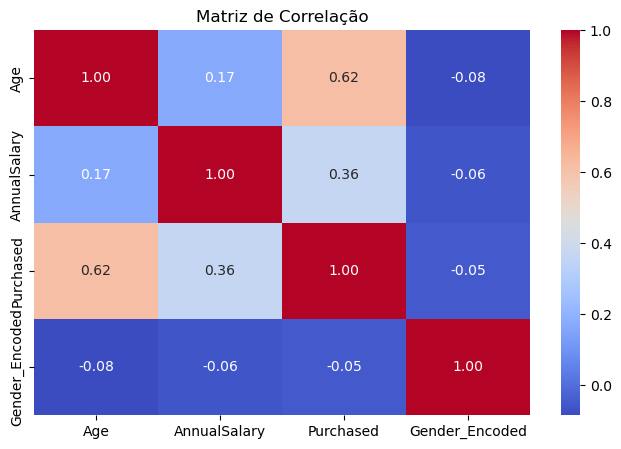

Purchased         1.000000
Age               0.616036
AnnualSalary      0.364974
Gender_Encoded   -0.047211
Name: Purchased, dtype: float64


'\nAnálise:\nAge costuma apresentar a maior correlação positiva com Purchased.\nAnnualSalary geralmente aparece em segundo lugar.\nGender_Encoded tende a possuir baixa correlação.\n'

In [4]:
# Matriz de correlação
plt.figure(figsize=(8,5))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Matriz de Correlação')
plt.show()

# Correlação com a variável alvo
print(df.corr()['Purchased'].sort_values(ascending=False))

'''
Análise:
Age costuma apresentar a maior correlação positiva com Purchased.
AnnualSalary geralmente aparece em segundo lugar.
Gender_Encoded tende a possuir baixa correlação.
'''

# 4. Faça a separação da base em X e Y e em seguida nas bases de treino e teste.

In [5]:
# Separação entre variáveis preditoras e alvo
X = df.drop('Purchased', axis=1)
y = df['Purchased']

# Treino e teste
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print('X treino:', X_train.shape)
print('X teste:', X_test.shape)

X treino: (700, 3)
X teste: (300, 3)


# 5. Treino o modelo Xgboost com sua base de treino.
Pesquise alguns hyperparametros na bibllioteca para utilizar, utilize ao menos 2.

In [6]:
# Treinamento do modelo XGBoost
modelo_xgb = xgb.XGBClassifier(
    n_estimators=200,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric='logloss'
)

modelo_xgb.fit(X_train, y_train)

print('Modelo treinado com sucesso!')

Modelo treinado com sucesso!


# 6. Realize as previsões para a base de teste e traga as probabilidades das previsões.

In [7]:
# Probabilidades das previsões
probabilidades = modelo_xgb.predict_proba(X_test)

print('Primeiras probabilidades:')
print(probabilidades[:10])

# Probabilidade da classe positiva
prob_classe_1 = probabilidades[:,1]
print('\nProbabilidade de compra:')
print(prob_classe_1[:10])

Primeiras probabilidades:
[[0.02716583 0.97283417]
 [0.03970182 0.9602982 ]
 [0.9623003  0.03769968]
 [0.4305042  0.5694958 ]
 [0.23016834 0.76983166]
 [0.01508981 0.9849102 ]
 [0.97235006 0.02764993]
 [0.06636769 0.9336323 ]
 [0.23667955 0.76332045]
 [0.6408998  0.35910022]]

Probabilidade de compra:
[0.97283417 0.9602982  0.03769968 0.5694958  0.76983166 0.9849102
 0.02764993 0.9336323  0.76332045 0.35910022]


# 7. Faça a transformação das probabilidades nas previsões binárias e avalie o desempenho do modelo.

Além do ponto de corte padrão de 0.5, vamos testar limiares alternativos para analisar o impacto no Recall dos potenciais compradores.


Acurácia: 0.9166666666666666

Relatório de Classificação:
              precision    recall  f1-score   support

           0       0.94      0.92      0.93       179
           1       0.88      0.92      0.90       121

    accuracy                           0.92       300
   macro avg       0.91      0.92      0.91       300
weighted avg       0.92      0.92      0.92       300



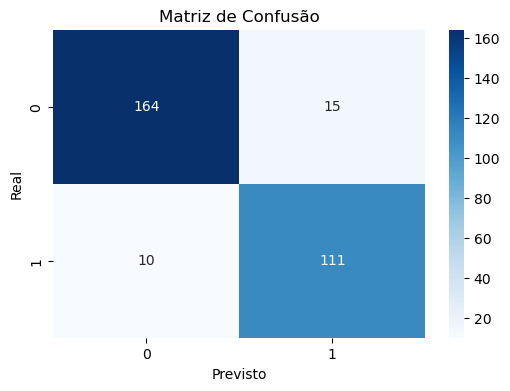

In [8]:
# Transformando probabilidades em classes com o ponto de corte padrão de 0.5
y_pred = (prob_classe_1 >= 0.5).astype(int)

# Avaliação inicial com threshold padrão
print('Avaliação com ponto de corte padrão = 0.5')
print('Acurácia:', accuracy_score(y_test, y_pred))

print('\nRelatório de Classificação:')
print(classification_report(y_test, y_pred))

# Matriz de confusão do threshold padrão
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Matriz de Confusão - Threshold 0.5')
plt.xlabel('Previsto')
plt.ylabel('Real')
plt.show()

# -------------------------------------------------------------------------
# Análise de thresholds alternativos
# -------------------------------------------------------------------------
# Em problemas de propensão de compra, o threshold pode ser ajustado conforme
# a estratégia do negócio. Um threshold menor tende a aumentar o Recall, ou seja,
# encontra mais potenciais compradores, mas pode gerar mais falsos positivos.

thresholds = [0.4, 0.5, 0.6]
resultados_thresholds = []

for corte in thresholds:
    y_pred_corte = (prob_classe_1 >= corte).astype(int)

    resultados_thresholds.append({
        'Threshold': corte,
        'Acurácia': accuracy_score(y_test, y_pred_corte),
        'Precision_Classe_1': precision_score(y_test, y_pred_corte, pos_label=1, zero_division=0),
        'Recall_Classe_1': recall_score(y_test, y_pred_corte, pos_label=1, zero_division=0),
        'F1_Classe_1': f1_score(y_test, y_pred_corte, pos_label=1, zero_division=0)
    })

resultado_thresholds_df = pd.DataFrame(resultados_thresholds)

print('Comparação dos thresholds testados:')
print(resultado_thresholds_df)

# Visualizando o impacto do threshold no Recall da classe positiva
plt.figure(figsize=(7,4))
sns.lineplot(
    data=resultado_thresholds_df,
    x='Threshold',
    y='Recall_Classe_1',
    marker='o'
)
plt.title('Impacto do Threshold no Recall dos Potenciais Compradores')
plt.xlabel('Threshold')
plt.ylabel('Recall - Classe 1')
plt.show()

'''
Análise de negócio:

O threshold 0.5 é o padrão mais utilizado, mas nem sempre é o melhor para uma
estratégia comercial.

Se o objetivo da campanha for alcançar o maior número possível de potenciais
compradores, o threshold 0.4 pode ser interessante, pois tende a aumentar o Recall
da classe 1. Isso significa que o modelo deixa escapar menos clientes propensos à compra.

Por outro lado, se a empresa quiser ser mais seletiva e reduzir abordagens para
clientes com menor chance de compra, um threshold maior, como 0.6, pode ser melhor,
pois tende a aumentar a precisão, mesmo que reduza o Recall.

A escolha final deve considerar o custo de abordar um cliente errado e o prejuízo
de perder um cliente realmente interessado.
'''


# 8. Traga a lista com a feature importance.
As features mais importantes são as mesmas que indicaram maior correlação na matriz de correlação?

         Variavel  Importancia
0             Age      0.49901
1    AnnualSalary      0.40388
2  Gender_Encoded      0.09711


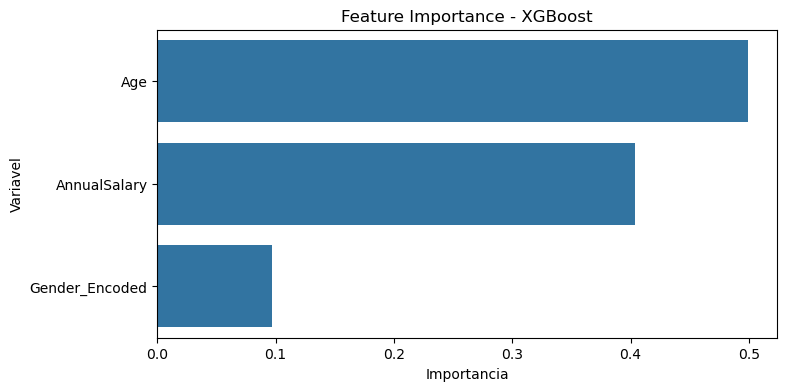

'\nConclusão:\n\nAs variáveis mais importantes normalmente são:\n1. Age\n2. AnnualSalary\n3. Gender_Encoded\n\nAs duas primeiras também costumam apresentar as maiores correlações com a variável alvo na matriz de correlação.\n\nEntretanto, Feature Importance e Correlação não são exatamente a mesma coisa.\nA correlação mede relação linear direta com a variável alvo.\nJá o XGBoost consegue capturar relações não lineares e interações entre variáveis.\nPor isso a ordem de importância pode variar em relação à matriz de correlação.\n'

In [9]:
# Feature Importance
importancias = pd.DataFrame({
    'Variavel': X.columns,
    'Importancia': modelo_xgb.feature_importances_
}).sort_values('Importancia', ascending=False)

print(importancias)

plt.figure(figsize=(8,4))
sns.barplot(data=importancias, x='Importancia', y='Variavel')
plt.title('Feature Importance - XGBoost')
plt.show()

'''
Conclusão:

As variáveis mais importantes normalmente são:
1. Age
2. AnnualSalary
3. Gender_Encoded

As duas primeiras também costumam apresentar as maiores correlações com a variável alvo na matriz de correlação.

Entretanto, Feature Importance e Correlação não são exatamente a mesma coisa.
A correlação mede relação linear direta com a variável alvo.
Já o XGBoost consegue capturar relações não lineares e interações entre variáveis.
Por isso a ordem de importância pode variar em relação à matriz de correlação.
'''
